# Value at Risk and Expected Shortfall of the book

Daily 1-day VaR 99% and ES 97.5% of the 10 M€ book, for every trading day from 2 January 2012 to 21 October 2026 (gold table `fact_var`), produced by [`pipeline/var.py`](../pipeline/var.py).

| Method | How tomorrow's loss distribution is built |
|---|---|
| Historical simulation (HS) | The last 250 book P&Ls, equally weighted |
| Parametric (EWMA, GARCH, champion) | A normal distribution scaled by a 1-day volatility forecast; the champion is GJR-GARCH, selected in [`02_volatility`](02_volatility.ipynb) |
| Filtered historical simulation (FHS) | The last 500 book returns, each divided by the GJR forecast for its day, rescaled by the forecast for tomorrow (Barone-Adesi, Giannopoulos and Vosper, 1999; Hull and White, 1998) |

**Conventions.** VaR and ES are positive losses in euros. A figure computed at the close of day t covers day t+1 and is stored under t+1. GARCH-type models are refitted at the start of every month from 2010 on all past data, so FHS has 500 standardised returns from 2012. Normal multipliers: 2.326 for VaR 99%, 2.338 for ES 97.5%.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "requirements.txt").exists())
GOLD = ROOT / "data" / "gold"
INK, INK2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e6e5e1", "#fcfcfb"
LOSS = "#c4c2bc"  # context marks: visible, behind the VaR lines
METHOD_COLORS = {"hs": "#a9a8a3", "param_ewma": "#1baf7a", "param_champion": "#2a78d6", "fhs": "#eb6834"}
METHOD_NAMES = {
    "hs": "Historical simulation",
    "param_ewma": "Parametric (EWMA)",
    "param_garch": "Parametric (GARCH)",
    "param_champion": "Parametric (GJR)",
    "fhs": "Filtered historical simulation",
}
plt.rcParams.update(
    {
        "figure.figsize": (9, 3.6),
        "figure.dpi": 110,
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "axes.edgecolor": GRID,
        "axes.labelcolor": INK2,
        "axes.titlecolor": INK,
        "axes.titlesize": 11,
        "axes.titleweight": "bold",
        "axes.titlelocation": "left",
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.color": GRID,
        "grid.linewidth": 0.6,
        "xtick.color": INK2,
        "ytick.color": INK2,
        "lines.linewidth": 1.5,
        "legend.frameon": False,
        "font.size": 9,
    }
)

fact = pd.read_parquet(GOLD / "fact_var.parquet").assign(for_date=lambda d: pd.to_datetime(d["for_date"]))
var = fact.pivot(index="for_date", columns="method_id", values="var_99_eur")[list(METHOD_NAMES)]
es = fact.pivot(index="for_date", columns="method_id", values="es_975_eur")[list(METHOD_NAMES)]
pnl = (
    pd.read_parquet(GOLD / "fact_pnl.parquet")
    .assign(date=lambda d: pd.to_datetime(d["date"]))
    .groupby("date")["pnl_eur"]
    .sum()
)
loss = (-pnl).reindex(var.index)  # realised loss on the day each figure covers; empty for the last day
print(f"{len(var)} days, {var.index[0]:%d %b %Y} to {var.index[-1]:%d %b %Y}")

3824 days, 02 Jan 2012 to 21 Oct 2026


## 1. Fourteen years of VaR

,mean VaR (kEUR),lowest VaR (kEUR),highest VaR (kEUR),mean ES (kEUR),mean ES / VaR
method_id,,,,,
Historical simulation,161.85,92.53,445.30,163.92,1.03
Parametric (EWMA),131.32,58.40,656.18,131.96,1.00
Parametric (GARCH),138.58,75.13,689.82,139.26,1.00
Parametric (GJR),138.19,72.53,907.87,138.87,1.00
Filtered historical simulation,149.86,67.64,1231.08,155.60,1.04


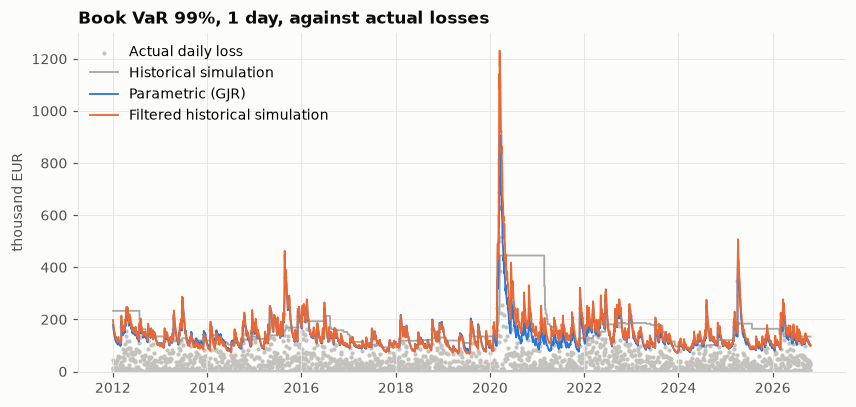

In [2]:
summary = pd.DataFrame(
    {
        "mean VaR (kEUR)": var.mean() / 1000,
        "lowest VaR (kEUR)": var.min() / 1000,
        "highest VaR (kEUR)": var.max() / 1000,
        "mean ES (kEUR)": es.mean() / 1000,
        "mean ES / VaR": (es / var).mean(),
    }
).rename(index=METHOD_NAMES)
fig, ax = plt.subplots(figsize=(9, 4))
ax.scatter(loss.index, loss.clip(lower=0) / 1000, s=3, color=LOSS, label="Actual daily loss")
for method in ["hs", "param_champion", "fhs"]:
    ax.plot(
        var.index, var[method] / 1000, color=METHOD_COLORS[method], linewidth=1.2, label=METHOD_NAMES[method]
    )
ax.set(title="Book VaR 99%, 1 day, against actual losses", ylabel="thousand EUR", ylim=(0, 1300))
ax.legend(loc="upper left")
summary.round(2)

The methods agree in calm years and part in stress. Over 2012–2026 the mean VaR ranges from 131 k€ (parametric EWMA) to 162 k€ (historical simulation); in 2020 the peaks range from 445 k€ (HS) to 1,231 k€ (FHS). Today's VaR, for 21 October 2026, is 91 to 134 k€ depending on the method, about 1% of the book.

## 2. March 2020: who reacted, and when

In [3]:
key_days = [
    "2020-02-20",
    "2020-02-28",
    "2020-03-09",
    "2020-03-12",
    "2020-03-16",
    "2020-03-31",
    "2020-06-30",
    "2020-12-31",
    "2021-03-31",
]
calm = var.loc["2020-02-20"]
doubled = {
    METHOD_NAMES[m]: var.loc["2020-02-21":"2020-12-31", m][lambda v, m=m: v >= 2 * calm[m]]
    .index[0]
    .strftime("%d %b %Y")
    for m in var.columns
}
peaks = {
    METHOD_NAMES[m]: f"{var.loc['2020', m].max() / 1000:,.0f} k on {var.loc['2020', m].idxmax():%d %b}"
    for m in var.columns
}
print("First day at twice the 20 February level:", doubled)
print("2020 peak:", peaks)
print(f"Book loss on 12 March 2020: {loss.loc['2020-03-12'] / 1000:,.0f} k")
table = (var.loc[key_days] / 1000).round(0).rename(columns=METHOD_NAMES)
table.insert(0, "actual loss", (loss.loc[key_days] / 1000).round(0))
table

First day at twice the 20 February level: {'Historical simulation': '17 Mar 2020', 'Parametric (EWMA)': '28 Feb 2020', 'Parametric (GARCH)': '28 Feb 2020', 'Parametric (GJR)': '25 Feb 2020', 'Filtered historical simulation': '25 Feb 2020'}
2020 peak: {'Historical simulation': '445 k on 19 Mar', 'Parametric (EWMA)': '656 k on 25 Mar', 'Parametric (GARCH)': '690 k on 25 Mar', 'Parametric (GJR)': '908 k on 17 Mar', 'Filtered historical simulation': '1,231 k on 17 Mar'}
Book loss on 12 March 2020: 687 k


method_id,actual loss,Historical simulation,Parametric (EWMA),Parametric (GARCH),Parametric (GJR),Filtered historical simulation
for_date,,,,,,
2020-02-20,32.0,135.0,101.0,110.0,98.0,124.0
2020-02-28,194.0,158.0,215.0,233.0,328.0,445.0
2020-03-09,502.0,202.0,267.0,288.0,385.0,522.0
2020-03-12,687.0,220.0,369.0,397.0,556.0,754.0
2020-03-16,518.0,237.0,529.0,577.0,801.0,1086.0
2020-03-31,12.0,445.0,608.0,612.0,648.0,879.0
2020-06-30,-76.0,445.0,236.0,210.0,226.0,310.0
2020-12-31,0.0,445.0,115.0,111.0,104.0,142.0
2021-03-31,-24.0,182.0,102.0,104.0,85.0,116.0


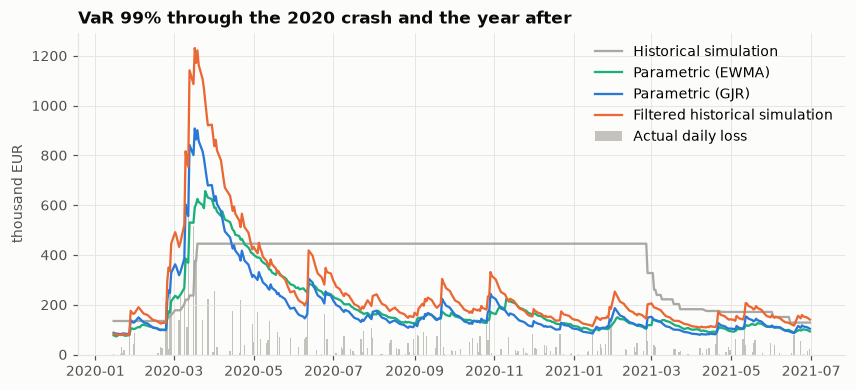

In [4]:
window = slice("2020-01-15", "2021-06-30")
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.bar(
    loss.loc[window].index,
    loss.loc[window].clip(lower=0) / 1000,
    width=1.0,
    color=LOSS,
    label="Actual daily loss",
)
for method in ["hs", "param_ewma", "param_champion", "fhs"]:
    ax.plot(
        var.loc[window].index,
        var.loc[window, method] / 1000,
        color=METHOD_COLORS[method],
        label=METHOD_NAMES[method],
    )
ax.set(title="VaR 99% through the 2020 crash and the year after", ylabel="thousand EUR")
ax.legend(loc="upper right");

The volatility-driven methods react within days: the GJR parametric VaR and FHS doubled on 25 February, EWMA and GARCH on 28 February, before the worst losses of 9, 12 and 16 March. Historical simulation doubled only on 17 March, after them: its 1% quantile is the second or third worst of 250 equally weighted days, so it moves only once several crash days have entered the window. For 12 March, the worst day (a loss of 687 k€), its VaR was 220 k€ against 556 k€ for GJR and 754 k€ for FHS.

Historical simulation is also slow on the way down: it stays at 445 k€ from 19 March 2020 to 25 February 2021 and falls below 200 k€ only on 23 March 2021, when the crash days leave its 250-day window, while the GJR VaR is back to 104 k€ by the end of 2020. Pritsker (2006) documents this slow response of historical simulation to changes in volatility.

## 3. Expected Shortfall: how deep is the tail?

In [5]:
ratio = (es / var).rename(columns=METHOD_NAMES)
print("ES 97.5% / VaR 99%: mean over 2012-2026 and on the last day")
pd.DataFrame({"mean": ratio.mean(), "last day": ratio.iloc[-1]}).round(3)

ES 97.5% / VaR 99%: mean over 2012-2026 and on the last day


,mean,last day
method_id,,
Historical simulation,1.029,0.988
Parametric (EWMA),1.005,1.005
Parametric (GARCH),1.005,1.005
Parametric (GJR),1.005,1.005
Filtered historical simulation,1.045,1.193


For the parametric methods the ratio is fixed by the normal distribution (2.338 / 2.326 = 1.005): ES 97.5% and VaR 99% carry the same information. The empirical methods let the tail speak: FHS averages 1.045 and is 1.19 today, its 500 standardised returns containing the fat tails measured in [`00_stylized_facts`](00_stylized_facts.ipynb). This is the regulatory argument for ES (Basel Committee, 2019): it is coherent and subadditive (Artzner et al., 1999; Acerbi and Tasche, 2002), and it reflects the depth of the tail, which a normal VaR cannot.

## 4. Conclusions and consequences

| Finding | Consequence |
|---|---|
| Volatility-driven VaRs doubled by 25–28 February 2020, historical simulation on 17 March | HS is kept as a benchmark, not as the risk figure |
| HS stays at its peak for a year after the crash, then drops on a fixed date | Its capital figure would depend on the calendar, not on current risk |
| Normal ES adds nothing to normal VaR (ratio 1.005); FHS sees deeper tails | FHS is the candidate method for the risk figure, subject to the backtest |
| FHS peaked at 1.23 M€ in March 2020, well above the other methods | The backtest must check that it is not over-conservative in calm periods |

Which method to recommend is decided by the backtest in the next step: number of exceptions against the 1% expected (Kupiec), their clustering (Christoffersen) and the Basel traffic light, over 2012–2026, 2020 and 2022: see [`04_backtest`](04_backtest.ipynb).

## References

- Acerbi, C., & Tasche, D. (2002). On the coherence of expected shortfall. *Journal of Banking & Finance*, 26(7), 1487–1503.
- Artzner, P., Delbaen, F., Eber, J.-M., & Heath, D. (1999). Coherent measures of risk. *Mathematical Finance*, 9(3), 203–228.
- Barone-Adesi, G., Giannopoulos, K., & Vosper, L. (1999). VaR without correlations for portfolios of derivative securities. *Journal of Futures Markets*, 19(5), 583–602.
- Basel Committee on Banking Supervision (2019). *Minimum capital requirements for market risk*. Bank for International Settlements.
- Glosten, L. R., Jagannathan, R., & Runkle, D. E. (1993). On the relation between the expected value and the volatility of the nominal excess return on stocks. *Journal of Finance*, 48(5), 1779–1801.
- Hull, J., & White, A. (1998). Incorporating volatility updating into the historical simulation method for value-at-risk. *Journal of Risk*, 1(1), 5–19.
- J.P. Morgan/Reuters (1996). *RiskMetrics — Technical Document* (4th ed.).
- Pritsker, M. (2006). The hidden dangers of historical simulation. *Journal of Banking & Finance*, 30(2), 561–582.